# Modelado de Señales y Métodos de Estimación Lineal

Este cuaderno presenta el modelado de una señal senoidal continua con ruido gaussiano añadido y su posterior reconstrucción utilizando cuatro enfoques de optimización lineal y regularización bajo una base polinomial.

---

## 1. Generación de la Señal Original

La señal de prueba se modela como una función senoidal pura de frecuencia $1\text{ Hz}$ en el dominio continuo discretizado temporalmente:

$$y(x) = \sin(2\pi x)$$

Donde $x$ está definido en el intervalo $[0, 1]$. La siguiente celda importa las librerías necesarias (`numpy` y `matplotlib`), genera $N = 100$ muestras uniformemente espaciadas y calcula los valores correspondientes de la señal limpia.

<function matplotlib.pyplot.show(close=None, block=None)>

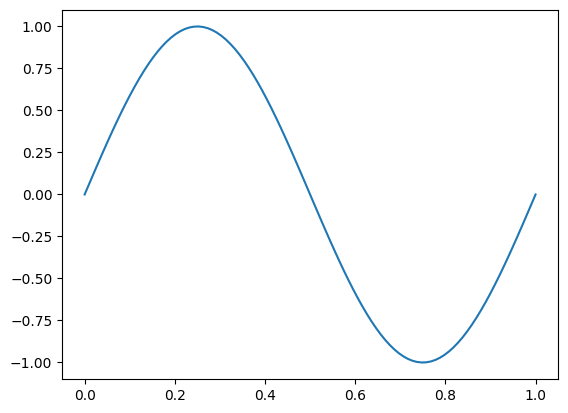

In [44]:
import numpy as np
import matplotlib.pyplot as plt
N = 100
x = np.linspace(0, 1, N)
x = x.reshape(-1,1)
y = np.sin(2*np.pi*x)
plt.plot(x,y)
plt.show

## 2. Adición de Ruido con Control de Relación Señal/Ruido (SNR)

Para simular condiciones reales, se añade ruido blanco gaussiano aditivo (AWGN) a la señal original. El ruido se modela como:

$$t_i = y(x_i) + n_i, \quad n_i \sim \mathcal{N}(0, \sigma_n^2)$$

La potencia del ruido $\sigma_n^2$ ($P_n$) se calcula a partir de la potencia de la señal limpia $P_s$ y de una Relación Señal/Ruido dada en decibelios ($\text{SNR}_{\text{dB}}$) mediante la siguiente relación física:

$$P_s = \frac{1}{N} \sum_{i=1}^{N} y_i^2$$

$$\text{SNR} = 10^{\frac{\text{SNR}_{\text{dB}}}{10}} = \frac{P_s}{P_n} \implies P_n = \frac{P_s}{10^{\frac{\text{SNR}_{\text{dB}}}{10}}}$$

La siguiente celda implementa esta función para contaminar la señal con un nivel de ruido controlado de $3\text{ dB}$.

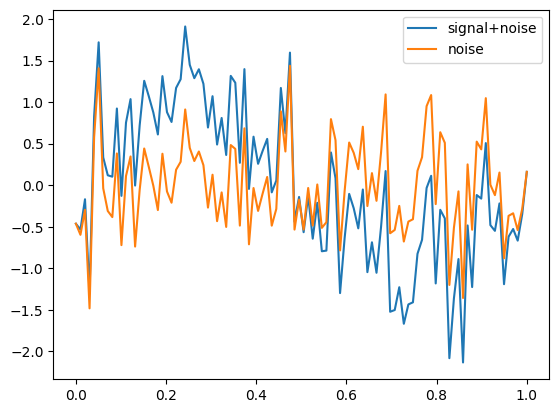

In [45]:
def snr_db(y_t, snt_db):
  Ps = np.mean(y_t**2)
  Pn = Ps/(10**(snt_db/10))
  n_o = np.random.normal(0, np.sqrt(Pn), size = y_t.shape)
  return y_t+n_o, n_o, Pn

t, n_o, sigma2 = snr_db(y, 3)
plt.plot(x, t, label = 'signal+noise')
plt.plot(x, n_o, label = 'noise')
plt.legend()
plt.show()

## 3. Matriz de Diseño y Planteamiento del Sistema

Para aproximar o reconstruir la señal a partir de los datos ruidosos, mapeamos los puntos de entrada $x$ a un espacio de características polinomiales mediante una **Matriz de Diseño** $\Phi$ de dimensión $N \times Q$, donde $Q-1$ es el grado máximo del polinomio:

$$\Phi = \begin{bmatrix}
1 & x_1 & x_1^2 & \dots & x_1^{Q-1} \\
1 & x_2 & x_2^2 & \dots & x_2^{Q-1} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & x_N & x_N^2 & \dots & x_N^{Q-1}
\end{bmatrix}$$

Queremos encontrar el vector de pesos $w = [w_0, w_1, \dots, w_{Q-1}]^T$ tal que $\hat{t} = \Phi w$ se aproxime a la señal original.

Asimismo, definimos la función analítica `solve` para resolver el sistema lineal regularizado por mínimos cuadrados utilizando la pseudoinversa:

$$w = (\Phi^T \Phi + l \cdot I)^{-1} \Phi^T t$$

donde $l$ es el parámetro de regularización Ridge (L2).

In [46]:
def Phi_f(x,Q):
  x = np.asarray(x.reshape(-1,1))
  return np.column_stack([x**q for q in range(Q)])

Phi = Phi_f(x, 2)

def solve(phi,y,l):
  inv = np.linalg.pinv(Phi.T@Phi+l*np.eye(phi.shape[1]))
  ninv = phi.T@y
  return inv@ninv

w = solve(Phi,x,1)

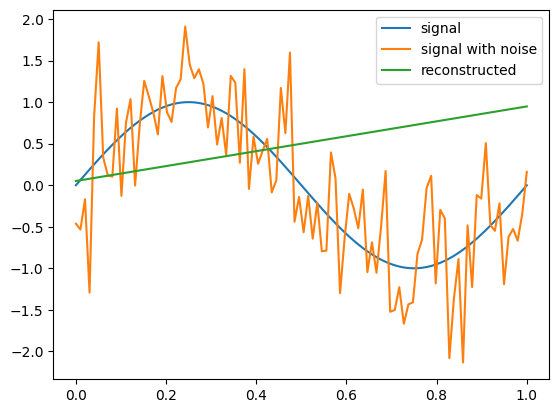

In [47]:
plt.plot(x,y,label = 'signal')
plt.plot(x,t,label = 'signal with noise')
plt.plot(x,Phi@w,label = 'reconstructed')
plt.legend()
plt.show()

## Deducción Matemática de los Métodos

Consideramos el modelo lineal:
$$t = \Phi w + n$$
donde $t \in \mathbb{R}^{N \times 1}$ es la señal con ruido, $\Phi \in \mathbb{R}^{N \times Q}$ es la matriz de diseño, $w \in \mathbb{R}^{Q \times 1}$ son los parámetros a estimar, y el ruido es Gaussiano blanco $n \sim \mathcal{N}(0, \sigma_n^2 I)$.

### 1. Mínimos Cuadrados (Least Squares - LS)
Este método busca minimizar la suma de los errores al cuadrado (la norma del residuo):
$$J_{LS}(w) = \frac{1}{2} \|t - \Phi w\|^2$$
Derivando respecto a $w$ e igualando a cero:
$$\nabla_w J_{LS}(w) = -\Phi^T (t - \Phi w) = 0 \implies \Phi^T \Phi w = \Phi^T t$$
$$w_{LS} = (\Phi^T \Phi)^{-1} \Phi^T t$$
*(Equivale a llamar a `solve(Phi, t, 0)`)*

### 2. Mínimos Cuadrados Regularizados (Regularized Least Squares - RLS)
También conocido como Regularización de Tikhonov o Ridge Regression. Agrega una penalización L2 sobre los pesos para evitar sobreajuste:
$$J_{RLS}(w) = \frac{1}{2} \|t - \Phi w\|^2 + \frac{\lambda}{2} \|w\|^2$$
Derivando respecto a $w$ e igualando a cero:
$$\nabla_w J_{RLS}(w) = -\Phi^T (t - \Phi w) + \lambda w = 0 \implies (\Phi^T \Phi + \lambda I) w = \Phi^T t$$
$$w_{RLS} = (\Phi^T \Phi + \lambda I)^{-1} \Phi^T t$$
*(Equivale a llamar a `solve(Phi, t, l)` con $l = \lambda > 0$)*

### 3. Máxima Verosimilitud (Maximum Likelihood - ML)
Bajo la asunción de ruido Gaussiano $t \sim \mathcal{N}(\Phi w, \sigma_n^2 I)$, la verosimilitud es:
$$p(t | w) = \left(2\pi \sigma_n^2\right)^{-N/2} \exp\left( -\frac{1}{2\sigma_n^2} \|t - \Phi w\|^2 \right)$$
La log-verosimilitud que queremos maximizar es:
$$\ln p(t | w) = -\frac{N}{2}\ln(2\pi\sigma_n^2) - \frac{1}{2\sigma_n^2} \|t - \Phi w\|^2$$
Maximizar la log-verosimilitud respecto a $w$ es equivalente a minimizar la suma de residuos al cuadrado (LS):
$$w_{ML} = (\Phi^T \Phi)^{-1} \Phi^T t$$
*(Por lo tanto, bajo ruido Gaussiano homocedástico, $w_{ML} = w_{LS}$)*

### 4. Máximo a Posteriori (Maximum A Posteriori - MAP)
Incorporamos conocimiento previo sobre los pesos mediante un prior Gaussiano $w \sim \mathcal{N}(0, \sigma_w^2 I)$:
$$p(w | t) \propto p(t | w) p(w)$$
Queremos maximizar la densidad a posteriori, o equivalentemente su logaritmo:
$$\ln p(w | t) = \ln p(t | w) + \ln p(w) + C$$
$$\ln p(w | t) = -\frac{1}{2\sigma_n^2}\|t - \Phi w\|^2 - \frac{1}{2\sigma_w^2}\|w\|^2 + C'$$
Maximizar esto equivale a minimizar:
$$J_{MAP}(w) = \frac{1}{2}\|t - \Phi w\|^2 + \frac{\sigma_n^2}{2\sigma_w^2}\|w\|^2$$
Esto tiene exactamente la misma forma que RLS si definimos el factor de regularización como $\lambda = \frac{\sigma_n^2}{\sigma_w^2}$:
$$w_{MAP} = \left(\Phi^T \Phi + \frac{\sigma_n^2}{\sigma_w^2} I\right)^{-1} \Phi^T t$$
*(Equivale a llamar a `solve(Phi, t, l)` con $l = \sigma_n^2 / \sigma_w^2$)*

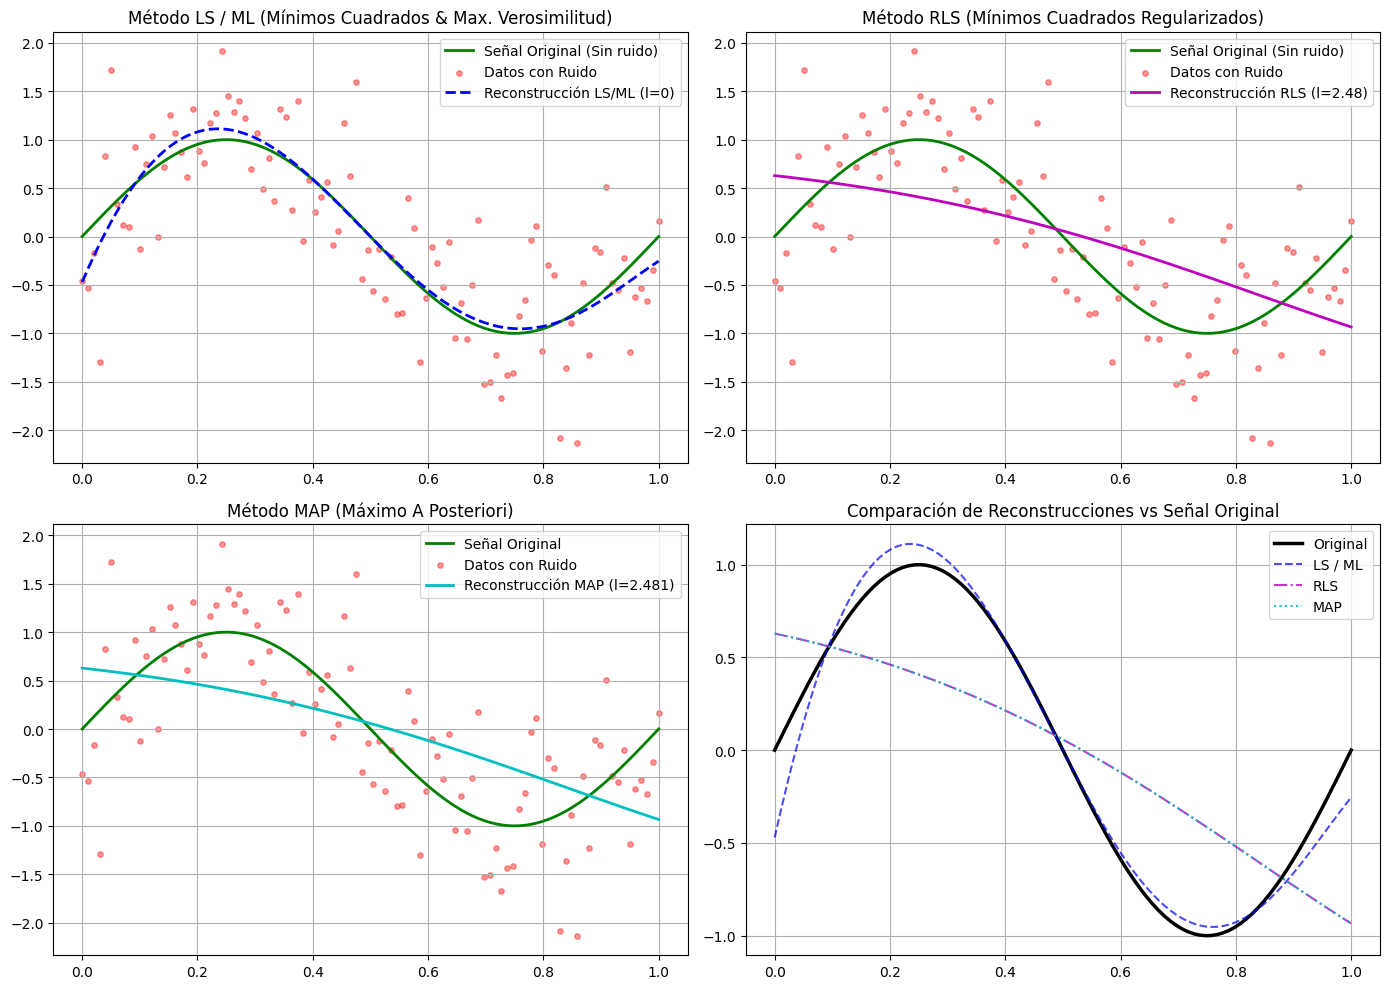

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# Corregimos la función solve para usar los parámetros locales y evitar errores lógicos
def solve(phi, target, l):
    # Usamos phi y target en lugar de las variables globales fijas
    inv = np.linalg.pinv(phi.T @ phi + l * np.eye(phi.shape[1]))
    ninv = phi.T @ target
    return inv @ ninv

# Para poder reconstruir la curva senoidal y no una línea recta,
# incrementamos el grado del polinomio a Q=5 para modelar la no linealidad.
Q_deg = 6
Phi_high = Phi_f(x, Q_deg)

# 1. LS (l = 0)
w_LS = solve(Phi_high, t, l=0.0)

# 2. RLS (l = lambda, por ejemplo l = 0.5)
l_rls = 2.48
w_RLS = solve(Phi_high, t, l=l_rls)

# 3. ML (idéntico a LS bajo ruido gaussiano)
w_ML = solve(Phi_high, t, l=0.0)

# 4. MAP (l = sigma_n^2 / sigma_w^2. Usamos la varianza estimada del ruido sigma2)
sigma_w2 = 0.1 # Suposición de varianza del prior
l_map = sigma2 / sigma_w2
w_MAP = solve(Phi_high, t, l=l_map)

# Graficar los resultados de los 4 métodos para contrastar
plt.figure(figsize=(14, 10))

# Subplot para LS y ML (que son equivalentes)
plt.subplot(2, 2, 1)
plt.plot(x, y, 'g-', label='Señal Original (Sin ruido)', linewidth=2)
plt.scatter(x, t, color='red', alpha=0.4, s=15, label='Datos con Ruido')
plt.plot(x, Phi_high @ w_LS, 'b--', label=f'Reconstrucción LS/ML (l=0)', linewidth=2)
plt.title('Método LS / ML (Mínimos Cuadrados & Max. Verosimilitud)')
plt.legend()
plt.grid(True)

# Subplot para RLS
plt.subplot(2, 2, 2)
plt.plot(x, y, 'g-', label='Señal Original (Sin ruido)', linewidth=2)
plt.scatter(x, t, color='red', alpha=0.4, s=15, label='Datos con Ruido')
plt.plot(x, Phi_high @ w_RLS, 'm-', label=f'Reconstrucción RLS (l={l_rls})', linewidth=2)
plt.title('Método RLS (Mínimos Cuadrados Regularizados)')
plt.legend()
plt.grid(True)

# Subplot para MAP
plt.subplot(2, 2, 3)
plt.plot(x, y, 'g-', label='Señal Original', linewidth=2)
plt.scatter(x, t, color='red', alpha=0.4, s=15, label='Datos con Ruido')
plt.plot(x, Phi_high @ w_MAP, 'c-', label=f'Reconstrucción MAP (l={l_map:.3f})', linewidth=2)
plt.title('Método MAP (Máximo A Posteriori)')
plt.legend()
plt.grid(True)

# Comparación general de todos sobre la señal original
plt.subplot(2, 2, 4)
plt.plot(x, y, 'k-', label='Original', linewidth=2.5)
plt.plot(x, Phi_high @ w_LS, 'b--', label='LS / ML', alpha=0.7)
plt.plot(x, Phi_high @ w_RLS, 'm-.', label='RLS', alpha=0.8)
plt.plot(x, Phi_high @ w_MAP, 'c:', label='MAP', alpha=0.9)
plt.title('Comparación de Reconstrucciones vs Señal Original')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Análisis Comparativo de Desempeño

### 1. Mínimos Cuadrados (LS) y Máxima Verosimilitud (ML)
* **Características**: No penalizan la magnitud de los pesos $w$. Buscan ajustarse lo más posible a los datos ruidosos observado.
* **Desempeño**:
  * Si el grado del polinomio ($Q$) es bajo, se comportan de manera aceptable.
  * Sin embargo, si $Q$ es alto, sufren drásticamente de **sobreajuste (overfitting)**, tratando de modelar el ruido aleatorio en lugar de la tendencia senoidal real. Por lo tanto, en presencia de ruido fuerte, suelen ofrecer el **peor desempeño general** debido a su alta varianza.

### 2. Regularized Least Squares (RLS)
* **Características**: Introduce una penalización L2 controlada por el parámetro de regularización $l$ (Ridge). Esto obliga a que los pesos se mantengan pequeños, suavizando la curva resultante.
* **Desempeño**: Ofrece un **buen desempeño** porque reduce la varianza del modelo significativamente a cambio de un sesgo pequeño. Al suavizar la curva, filtra eficazmente las oscilaciones abruptas producidas por el ruido.

### 3. Máximo a Posteriori (MAP)
* **Características**: Aprovecha información estadística previa tanto del ruido (mediante $\sigma_n^2$) como del comportamiento esperado de los coeficientes (mediante el prior gaussiano con varianza $\sigma_w^2$). Su parámetro de penalización óptimo está matemáticamente fundamentado como $l = \sigma_n^2 / \sigma_w^2$.
* **Desempeño**: Es típicamente el **mejor método** cuando se conocen o estiman correctamente las estadísticas del entorno, ya que la regularización no es heurística (como en RLS), sino que está directamente sintonizada con el nivel real de ruido presente en los datos.